# Projet : POKEDEX
objectif : créer une application Python offrant les fonctionnalités d'un pokédex

Les fonctionnalités à implémenter : 
- analyse et classifier les Pokémons
- prédire certaines propriétés

Jeu de données : 
- fichier csv "pokemon" (caractéristiques) :  https://www.kaggle.com/code/melearning-with-pokemon-predicting-legend/input?select=pokemon.csv
- banque d'image pokémon (1er gen) :  https://www.kaggle.com/datasets/mikoajkolman/pokemon-images-first-generation17000-files

### Rendue
- Notebook/code
- rapport : 
    - méthodo. adoptée
    - différentes méthodes et modèles testés
    - résultats + analyses/interprétations
    - limites approche + améliorations possibles

In [2]:
print("Hello, World!")

Hello, World!


In [3]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [6]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


## Niveau 1 : Données tabulaires

But : 
clustering : identifier les groupes + interprédation
statistiques de base => légendaire ou non + type du pokémon

A implémenter dans l'affichage: 
- groupe du Pokémon
- légendaire ou non

Tester plus. méthodes et justifier choix du modèle (comparaison du modèle)

Donnée 'pokémon.csv'

| Features name | Features' type |
| - | - |
|# | Float|
| Name | String 
Type 1 | String 
Type 2 | String 
HP | Float
Attack | Float
Defense | Float
Sp. Atk | Float
Sp. Def | Float
Speed | Float
Generation | Float
Legendary | Bool

[ Méthode à développer d'après Claude.com ]
1. Prétraitement des données : 
- entrées : stats
- cibles : types / légendaire
- séparation des données
2. Clustering
- différentes méthodes d'après stats
- choix nombre de clusters
- interprétation clusters (légendaire/types)
3. Classification 
4. Comparaison



In [7]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
# Importation des données

data = pd.read_csv('pokemon.csv', index_col="#")


# Prétraitement
stats = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]
y_leg, y_type = data["Legendary"].astype("int8"), data["Type 1"]

# Normalisation des données
scaler = StandardScaler()
X = scaler.fit_transform(data[stats])


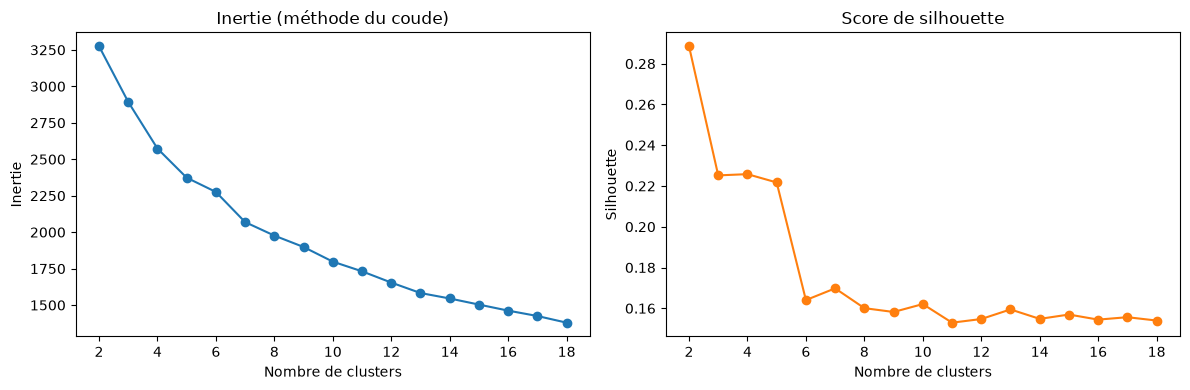

In [8]:
# K-means clustering

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

# Détermination du nombre de clusters optimal
inertias = []
score = []

for k in range(2, 19):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertias.append(kmeans.inertia_) # Méthode du coude 
    score.append(silhouette_score(X, kmeans.fit_predict(X))) # Score de silhouette


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(2, 19), inertias, marker="o")
axes[0].set_title("Inertie (méthode du coude)")
axes[0].set_xlabel("Nombre de clusters")
axes[0].set_ylabel("Inertie")

axes[1].plot(range(2, 19), score, marker="o", color="tab:orange")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("Nombre de clusters")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

D'après la méthode du coude et de la silhoutte, on repère que le nombre optimal de cluster est soit de 4 ou de 6

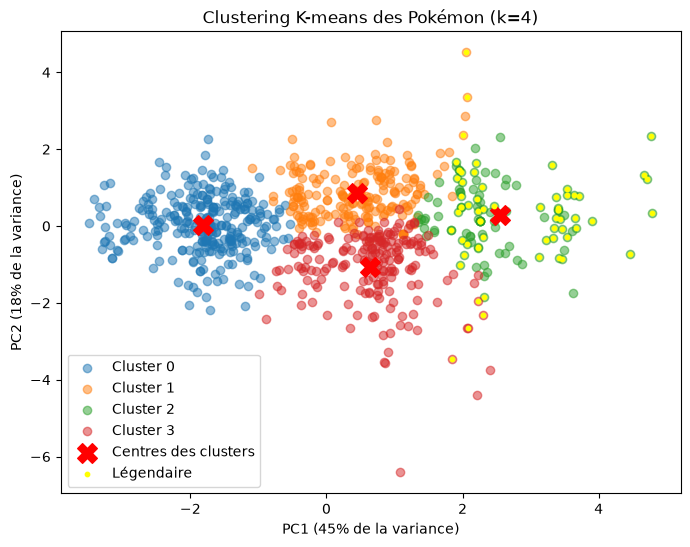

In [43]:
# Clustering avec le nombre de clusters optimal (k=4)
from sklearn.decomposition import PCA

kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(X)
labels = kmeans.predict(X)

# Projection sur les axes principaux
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)                       # X doit être standardisé
centres_pca = pca.transform(kmeans.cluster_centers_)

# Visualisation des clusters
plt.figure(figsize=(8, 6))
for c in range(4):
    plt.scatter(X_pca[labels ==c, 0], X_pca[labels ==c, 1], label=f"Cluster {c}", alpha = 0.5)
plt.scatter(centres_pca[:, 0], centres_pca[:, 1], c='red', marker='X', s=200, label='Centres des clusters')
plt.scatter(X_pca[y_leg == 1, 0], X_pca[y_leg == 1, 1], c="yellow", label="Légendaire", s = 10)
plt.title("Clustering K-means des Pokémon (k=4)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} de la variance)")
plt.legend()
plt.show()



In [35]:
# Analyse et interprétation des clusters

#Création d'un tableau récapitulatif des clusters 

data_clusters = data.copy()

# Ajout d'une colonne "Cluster" avec le numéro de cluster de chaque Pokémon

data_clusters["Cluster"] = labels

#Affichage du nombre de Pokémon par cluster
# Value counts compte combien de fois chaque valeur de cluster apparaît
# Sort index classe les résultats par ordre croissant de clusterts dans l'ordre des numéros de clusters

print(data_clusters["Cluster"].value_counts().sort_index())


Cluster
0    283
1    202
2    115
3    200
Name: count, dtype: int64


In [36]:
data_clusters

,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary,Cluster
#,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False,0
2,Ivysaur,Grass,Poison,60,62,63,80,80,60,1,False,1
3,Venusaur,Grass,Poison,80,82,83,100,100,80,1,False,1
4,Mega Venusaur,Grass,Poison,80,100,123,122,120,80,1,False,2
5,Charmander,Fire,NaN,39,52,43,60,50,65,1,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...
796,Diancie,Rock,Fairy,50,100,150,100,150,50,6,True,3
797,Mega Diancie,Rock,Fairy,50,160,110,160,110,110,6,True,2
798,Hoopa Confined,Psychic,Ghost,80,110,60,150,130,70,6,True,2


In [11]:
# Calcul des stats moyennes pour chaque cluster ( pour interpréter les caractéristiques principales des clusters)


# Regrouper tous les poké qui appartiennent à un même cluster et calculer la moyenne des stats pour chaque cluster 
moyennes_clusters = data_clusters.groupby("Cluster")[stats].mean()

# Arrondir à deux décimales

moyennes_clusters.round(2)

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
Cluster,,,,,,
0,50.11,53.98,51.89,48.06,49.21,49.45
1,69.29,84.31,65.91,83.52,73.04,94.62
2,94.30,114.02,94.57,117.65,103.69,95.45
3,81.92,88.92,101.00,71.26,84.58,52.68


Interprétation : 

- Cluster 0 = Pokémon aux statistiques globalement faibles ( toutes les moyennes aux alentours de 50 )
- Cluster 1 = Pokémon rapides
- Cluster 2 = Statistiques globalement élevées ( meilleurs moyennes sauf en défense ), Pokémon particulièrement offensifs ( attaque et attaque spéciale +++ )
- Cluster 3 = Pokémon défensifs

In [12]:
# Classification supervisée
# Pokémon légendaire ou non légendaire ?

X_leg = data[stats]
#X contient les 6 stats de chaque pokémon
Y_leg = data["Legendary"].astype("int")
#Y contient la réponse (1 si légendaire, 0 sinon)

print(X_leg.shape)
print(Y_leg.shape)

(800, 6)
(800,)


In [13]:
# Sépare les données pour entraînement puis test
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X_leg, Y_leg, test_size=0.2, random_state=42,
    stratify=Y_leg
)
# Stratify sert à conserver approximativement la même proportion de poké légendaires et non légendaires dans les deux ensembles (train et test)

print(X_train.shape)
print(X_test.shape)

(640, 6)
(160, 6)


In [14]:
# Import et entraînement du modèle KNN à 3 voisins
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=3)

model.fit(X_train, Y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [15]:
model.score(X_test, Y_test)

0.93125

In [16]:
# Voir les prédictions que le modèle a réellement faites
Y_pred = model.predict(X_test)
print(Y_pred)

[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0
 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0]


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

#On apprend la normalisation sur les données d'entraînement puis on applique cette même normalisation aux données de test
# Il est important de séparer les données avant de normaliser, sinon les données de test influencent la normalisation ( = fuite de données)

In [18]:
# on fait un KNN avec trois voisins et normalisations pour comparer au KNN à 3 voisins sans normalisation

model_scaled_3 = KNeighborsClassifier(n_neighbors=3)

model_scaled_3.fit(X_train_scaled, Y_train)
model_scaled_3.score(X_test_scaled, Y_test)


0.925

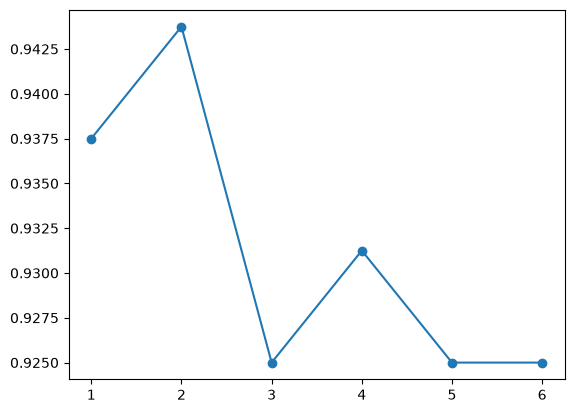

In [47]:
# Variation du k sur données normalisées

score_k = []
for k in range(1,7):
    model_scaled = KNeighborsClassifier(n_neighbors=k)

    model_scaled.fit(X_train_scaled, Y_train)
    score_k.append(model_scaled.score(X_test_scaled, Y_test))

plt.plot(range(1,7), score_k, marker='o')



Nous avons testé trois modèles KNN pour prédire si un Pokémon est légendaire ou non à partir de ses statistiques de combat. Nous avons modifié deux paramètres : des données normalisées ou non, et le nombre de voisins (3 ou 6). Les paramètres ont été modifiés un par un afin de pouvoir observer leur effet sur les résultats.

Observations suite aux tests KNN :

1. La normalisation n'a pas modifié l'accuracy pour le KNN à 3 voisins
2. Le passage de 3 à 6 voisins a légèrement diminué l'accuracy ( de 93,125% à 92,5%)


## Niveau 2 : Classification à partir d'images

But : dvlper modèle Ml pour identifier type d'un Pokémon à partir d'une image

Image d'un pokemon => le/les type(s)


## Niveau 3 : Pokédex complet

But : application Pokédex complet

Implémentations : 
- niveau 1
- niveau 2
- fonctionnalités trie par type
- utilisation caméra ordi : image de pokémon